# OpenCV DoG：复杂灰度场景与尺度比较

使用可重复生成的 **480×800 合成图像** 测试差分高斯，无需下载图片或安装其他依赖。
图像包含渐变照明、亮暗文字、不同尺寸圆盘、细粗线条、周期纹理和不同宽度的高斯光斑，
再加入成像模糊和随机噪声。

对同一输入分别滤波后相减：

$$D = G_{\sigma_1} * I - G_{\sigma_2} * I,\qquad \sigma_2>\sigma_1.$$

本例重点观察：亮暗结构的正负响应、缓慢背景的抑制、不同尺度对细节的选择，以及阈值分割的局限。
DoG 不执行数字识别，也不恢复模糊前的精确像素。按顺序运行全部单元格即可。


In [1]:
# 功能：在含渐变背景、亮暗目标、纹理与噪声的合成图像上测试 OpenCV DoG。
# 方法：生成场景 → 模糊加噪 → 浮点双尺度高斯差分 → 正负阈值与区域清理 → 多尺度和剖面对比。
# 注意事项：按顺序运行；sigma 单位为像素；保留差分负值；连通区域不等同于目标数量。
# 依赖：cv2、NumPy、Matplotlib；随机种子固定；不下载数据，不改变环境，不自动写出图片。
import cv2
import numpy as np
import matplotlib.pyplot as plt

seed = 7
image_height, image_width = 480, 800
blur_sigma = 1.2       # 模拟成像模糊的标准差，单位：像素
noise_sigma = 0.025    # 噪声标准差，像素值归一化至 0～1
sigma_narrow = 1.5
sigma_broad = 5.0
threshold_rel = 0.20   # 相对整个 DoG 最大绝对值的阈值；正负方向共用
min_area = 12          # 连通区域最小面积，单位：像素
scale_pairs = [(0.8, 2.4), (1.5, 5.0), (4.0, 12.0)]


def gaussian_dog(image, narrow_sigma, broad_sigma):
    """对同一浮点输入分别做窄、宽高斯滤波，返回两个滤波结果及有符号差分。"""
    if not 0 < narrow_sigma < broad_sigma:
        raise ValueError("需要满足 0 < sigma_narrow < sigma_broad")
    src = np.asarray(image, dtype=np.float64)
    narrow = cv2.GaussianBlur(
        src, (0, 0), sigmaX=narrow_sigma, sigmaY=narrow_sigma,
        borderType=cv2.BORDER_REFLECT_101
    )
    broad = cv2.GaussianBlur(
        src, (0, 0), sigmaX=broad_sigma, sigmaY=broad_sigma,
        borderType=cv2.BORDER_REFLECT_101
    )
    return narrow, broad, narrow - broad


def show_gray(ax, image, title):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


print("OpenCV version:", cv2.__version__)


OpenCV version: 4.13.0


## 1. 生成复杂场景

| 位置 | 图像内容 |
|---|---|
| 上方 | 亮文字 `DoG 123` 与暗文字 `OpenCV` |
| 中部 | 半径为 10、22、38 像素的亮、暗圆盘 |
| 下部 | 细亮线、粗暗线和周期纹理 |
| 底部 | 宽度 σ=3、8、16 像素的亮、暗高斯光斑 |

左图是合成的清晰场景，右图是后续所有滤波共用的模糊含噪输入。


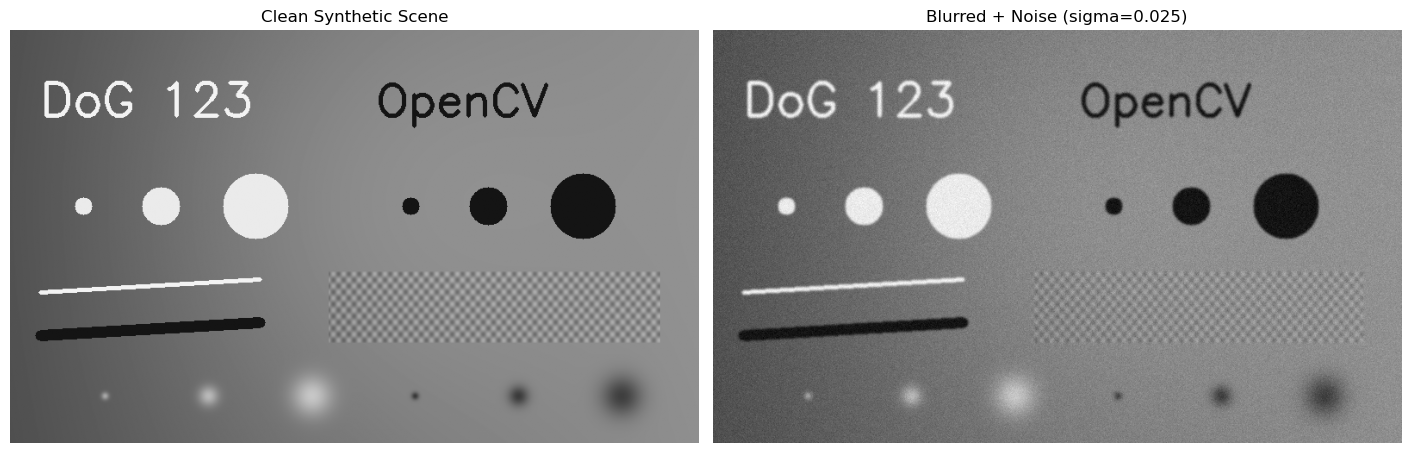

In [2]:
yy, xx = np.mgrid[:image_height, :image_width]
# 缓慢变化的照明：水平渐变 + 大尺度亮斑
background = (
    0.30 + 0.25 * xx / (image_width - 1)
    + 0.12 * np.exp(-((xx - 400) ** 2 + (yy - 200) ** 2) / (2 * 220.0 ** 2))
)
clean_img = background.astype(np.float64).copy()
font = cv2.FONT_HERSHEY_SIMPLEX
cv2.putText(clean_img, "DoG 123", (35, 100), font, 1.8, 0.95, 3)
cv2.putText(clean_img, "OpenCV", (425, 100), font, 1.7, 0.08, 3)

for center_x, radius in zip([85, 175, 285], [10, 22, 38]):
    cv2.circle(clean_img, (center_x, 205), radius, 0.92, thickness=-1)
for center_x, radius in zip([465, 555, 665], [10, 22, 38]):
    cv2.circle(clean_img, (center_x, 205), radius, 0.08, thickness=-1)

cv2.line(clean_img, (35, 305), (290, 290), 0.95, thickness=3)
cv2.line(clean_img, (35, 355), (290, 340), 0.08, thickness=12)
texture_region = (xx >= 370) & (xx < 755) & (yy >= 280) & (yy < 365)
texture = 0.12 * np.sin(2 * np.pi * xx / 12) * np.sin(2 * np.pi * yy / 14)
clean_img[texture_region] += texture[texture_region]

spot_row = 425
for sign, centers in [(1.0, [110, 230, 350]), (-1.0, [470, 590, 710])]:
    for center_x, spot_sigma in zip(centers, [3.0, 8.0, 16.0]):
        clean_img += sign * 0.30 * np.exp(
            -((xx - center_x) ** 2 + (yy - spot_row) ** 2) / (2 * spot_sigma ** 2)
        )
clean_img = np.clip(clean_img, 0, 1)

blurred_img = cv2.GaussianBlur(clean_img, (0, 0), sigmaX=blur_sigma)
rng = np.random.default_rng(seed)
input_img = np.clip(
    blurred_img + rng.normal(0, noise_sigma, clean_img.shape), 0, 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
show_gray(axes[0], clean_img, "Clean Synthetic Scene")
show_gray(axes[1], input_img, f"Blurred + Noise (sigma={noise_sigma})")
plt.show()


## 2. 双尺度高斯滤波与有符号差分

下面两次高斯滤波均以 `input_img` 为输入。图中的红色表示正响应，蓝色表示负响应。
亮目标中心通常出现正响应，暗目标中心通常出现负响应；边界两侧也会出现符号相反的响应。
因此不能简单把所有正、负响应分别理解成完整的亮、暗物体。


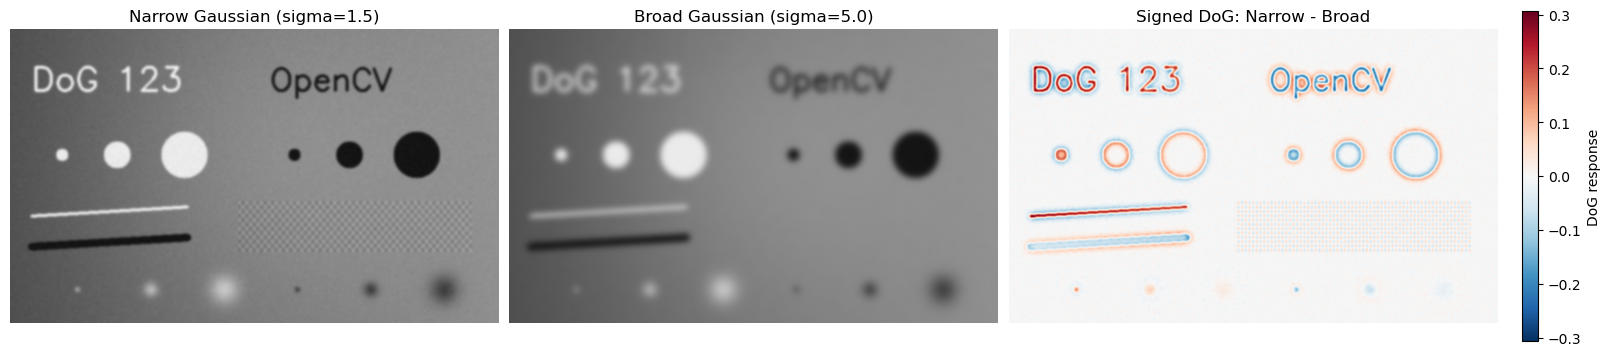

DoG range: [-0.24225, 0.30677]


In [3]:
narrow_img, broad_img, dog = gaussian_dog(input_img, sigma_narrow, sigma_broad)
dog_limit = max(float(np.abs(dog).max()), np.finfo(np.float64).eps)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
show_gray(axes[0], narrow_img, f"Narrow Gaussian (sigma={sigma_narrow})")
show_gray(axes[1], broad_img, f"Broad Gaussian (sigma={sigma_broad})")
dog_display = axes[2].imshow(dog, cmap="RdBu_r", vmin=-dog_limit, vmax=dog_limit)
axes[2].set_title("Signed DoG: Narrow - Broad")
axes[2].axis("off")
fig.colorbar(dog_display, ax=axes[2], shrink=0.7, label="DoG response")
plt.show()
print(f"DoG range: [{dog.min():.5f}, {dog.max():.5f}]")


## 3. 分别提取正、负响应

两种符号使用相同的绝对阈值：

$$T = \mathrm{threshold\_rel}\times\max |D|,\qquad M_+ = (D>T),\quad M_- = (D<-T).$$

分别对二值掩膜做 3×3 闭运算，并按连通区域面积去除小碎片。
这里保留全部面积达标区域，不填洞，以保留纹理及边界响应的结构。
比较清理前后，可以看到弱纹理和噪声也可能超过阈值，而细线也可能被面积筛选丢弃。


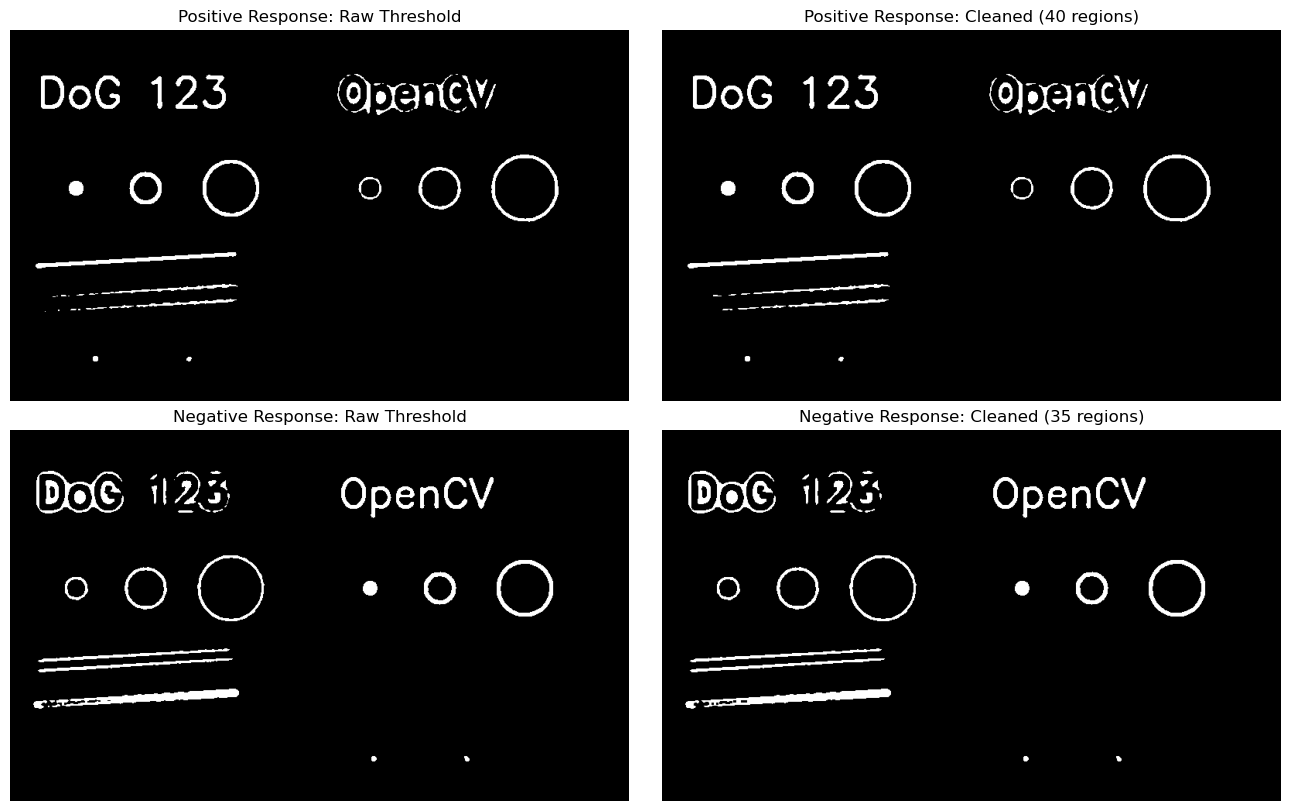

Absolute threshold: 0.06135
Retained connected regions: positive=40, negative=35
Connected regions describe response fragments, not recognized object counts.


In [4]:
threshold_abs = threshold_rel * float(np.abs(dog).max())
positive_raw = dog > threshold_abs
negative_raw = dog < -threshold_abs


def clean_response_mask(binary_mask, minimum_area):
    kernel = np.ones((3, 3), dtype=np.uint8)
    closed = cv2.morphologyEx(
        binary_mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel
    )
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    cleaned = np.zeros_like(closed, dtype=bool)
    kept_count = 0
    for region_id in range(1, n_labels):
        if stats[region_id, cv2.CC_STAT_AREA] >= minimum_area:
            cleaned[labels == region_id] = True
            kept_count += 1
    return cleaned, kept_count


positive_mask, positive_count = clean_response_mask(positive_raw, min_area)
negative_mask, negative_count = clean_response_mask(negative_raw, min_area)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
show_gray(axes[0, 0], positive_raw, "Positive Response: Raw Threshold")
show_gray(axes[0, 1], positive_mask, f"Positive Response: Cleaned ({positive_count} regions)")
show_gray(axes[1, 0], negative_raw, "Negative Response: Raw Threshold")
show_gray(axes[1, 1], negative_mask, f"Negative Response: Cleaned ({negative_count} regions)")
plt.show()
print(f"Absolute threshold: {threshold_abs:.5f}")
print(f"Retained connected regions: positive={positive_count}, negative={negative_count}")
print("Connected regions describe response fragments, not recognized object counts.")


## 4. 比较三个尺度

对同一个含噪输入计算三组 DoG，并使用**统一的对称色标**，避免自动缩放造成强弱比较失真。
较小尺度可观察细文字、纹理与细线，较大尺度可观察较宽光斑和粗结构的响应。
随着尺度改变，同一个目标的响应强度、符号分布和形状也可能变化；大圆盘经常主要表现为边缘环带。


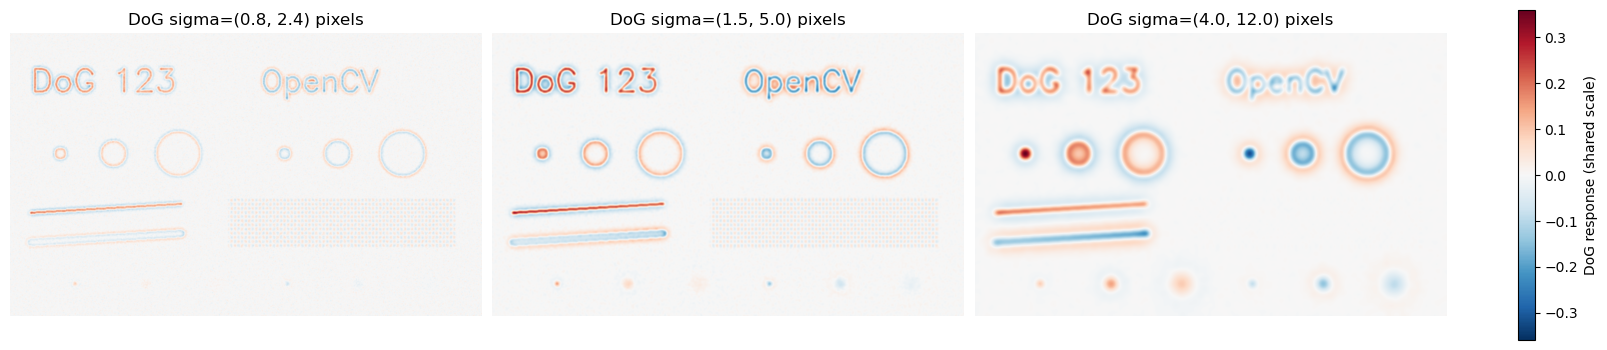

In [5]:
scale_dogs = [gaussian_dog(input_img, small, large)[2] for small, large in scale_pairs]
shared_limit = max(
    max(float(np.abs(response).max()) for response in scale_dogs),
    np.finfo(np.float64).eps
)
fig, axes = plt.subplots(1, len(scale_pairs), figsize=(16, 4.8), constrained_layout=True)
for ax, (small, large), response in zip(axes, scale_pairs, scale_dogs):
    display = ax.imshow(response, cmap="RdBu_r", vmin=-shared_limit, vmax=shared_limit)
    ax.set_title(f"DoG sigma=({small}, {large}) pixels")
    ax.axis("off")
fig.colorbar(display, ax=list(axes), shrink=0.7, label="DoG response (shared scale)")
plt.show()


## 5. 底部光斑的横向剖面

在 `y=425` 处比较输入与主尺度 DoG。上图包含宽度为 3、8、16 像素的亮、暗光斑和渐变背景；
下图显示相同位置的有符号响应。两个面板使用同一横坐标，纵轴分别为灰度值和 DoG 响应。

可以修改第一个代码单元格中的 `sigma_narrow`、`sigma_broad`、`noise_sigma`、
`threshold_rel`、`min_area` 和 `scale_pairs`，然后从头重新运行。
阈值与区域清理得到的是响应分割，不能据此判断已经恢复原图或准确识别全部物体。


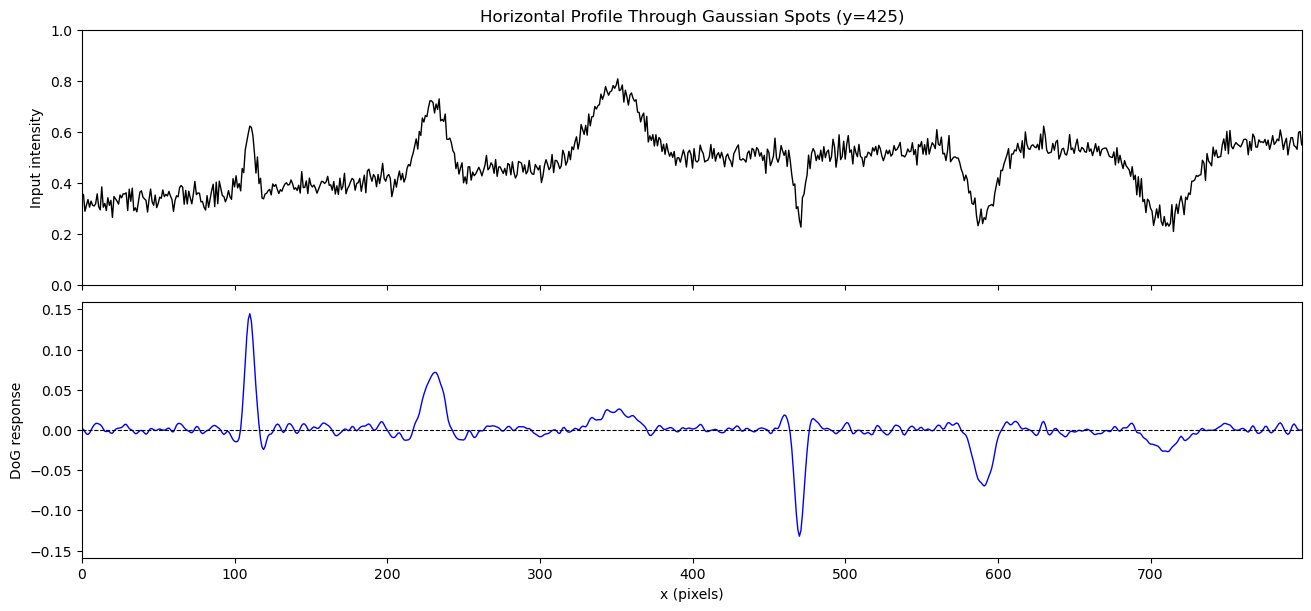

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
axes[0].plot(np.arange(image_width), input_img[spot_row], color="black", linewidth=1)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Input intensity")
axes[0].set_title(f"Horizontal Profile Through Gaussian Spots (y={spot_row})")
axes[1].plot(np.arange(image_width), dog[spot_row], color="blue", linewidth=1)
axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
profile_limit = max(float(np.abs(dog[spot_row]).max()) * 1.1, np.finfo(np.float64).eps)
axes[1].set_ylim(-profile_limit, profile_limit)
axes[1].set_ylabel("DoG response")
axes[1].set_xlabel("x (pixels)")
axes[1].set_xlim(0, image_width - 1)
plt.show()
